In [1]:
import numpy as np

ratings = np.loadtxt("ml-32m/ratings.csv", delimiter = ",", skiprows= 1)

In [2]:
cols = ['userId', 'movieId', 'rating', 'timestamp']

col_to_ind = {col:ind for ind,col in enumerate(cols)}

In [3]:
users_to_index = {}
index_to_users = []

movies_to_index = {}
index_to_movies = []

data_by_users = []
data_by_movies = []

In [4]:
len(ratings[:,col_to_ind["userId"]])

32000204

In [5]:
index_to_users = np.unique(ratings[:,col_to_ind["userId"]]).tolist()
users_to_index = {user:index for index,user in enumerate(index_to_users)}


index_to_movies = np.unique(ratings[:,col_to_ind["movieId"]]).tolist()
movies_to_index = {movie:index for index,movie in enumerate(index_to_movies)}

In [6]:
def process_user_ratings(ratings_arr,index_to_users):
  data_by_users =  [[] for _ in range(len(index_to_users))]

  for row in ratings_arr:
    user = row[col_to_ind["userId"]]
    movie = row[col_to_ind["movieId"]]
    rating = row[col_to_ind["rating"]]

    data_by_users[users_to_index[user]].append((movies_to_index[movie],rating))

  return data_by_users

data_by_users = process_user_ratings(ratings,index_to_users)

In [7]:
def process_movie_ratings(ratings_arr,index_to_movies):
  data_by_movies =  [[] for _ in range(len(index_to_movies))]

  for row in ratings_arr:
    user = row[col_to_ind["userId"]]
    movie = row[col_to_ind["movieId"]]
    rating = row[col_to_ind["rating"]]

    data_by_movies[movies_to_index[movie]].append((users_to_index[user],rating))

  return data_by_movies

data_by_movies = process_movie_ratings(ratings,index_to_movies)

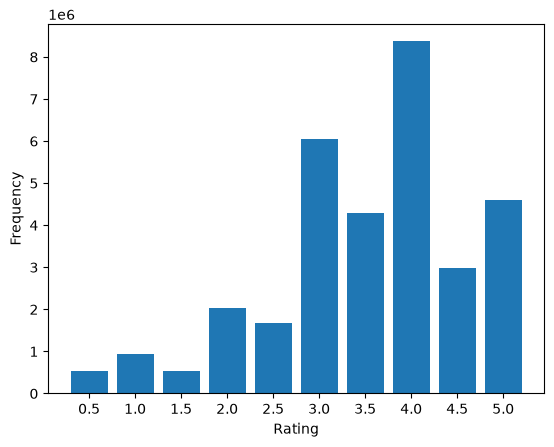

In [61]:
from matplotlib import pyplot as plt
from collections import Counter


ratings_counter = Counter(ratings[:,col_to_ind["rating"]])

ratings_counts = list(zip(list(ratings_counter.keys()), list(ratings_counter.values())))

ratings_counts.sort(key = lambda item : item[0])

ratings_order = [str(item[0]) for item in ratings_counts]
ratings_freq = [item[1] for item in ratings_counts]

plt.bar(ratings_order, ratings_freq)

plt.xlabel("Rating")
plt.ylabel("Frequency")
plt.savefig("images/ratings_distribution.svg")
plt.show()

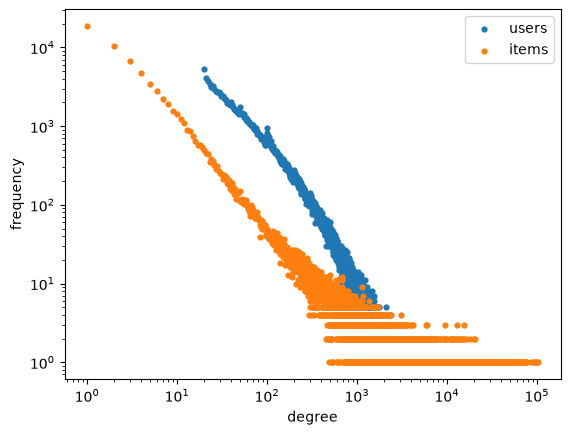

In [76]:

user_ratings_degree_count = [len(x) for x in data_by_users]
user_ratings_degree = Counter(user_ratings_degree_count)

item_ratings_degree_count = [len(x) for x in data_by_movies]
item_ratings_degree = Counter(item_ratings_degree_count)


#plt.figure(figsize = (8,8))
plt.scatter(user_ratings_degree.keys(),user_ratings_degree.values(), s = 12, label = 'users')
plt.scatter(item_ratings_degree.keys(),item_ratings_degree.values(), s = 12, label = "items")
plt.legend()
plt.xlabel("degree")
plt.ylabel("frequency")
plt.xscale("log")
plt.yscale("log")
plt.savefig("images/power_law.svg")
plt.show()


In [ ]:
import csv 

movie_db = []


with open("ml-32m/movies.csv") as f: 
    reader = csv.reader(f)
    
    headers = next(reader)
    
    for movie_id, title, genres in reader: 
        movie_db.append((movie_id,title,genres))
        


In [25]:
genre_list = []

for movie_id, title, genres in movie_db: 
    for genre in genres.split("|"): 
        genre_list.append(genre)
        
genre_list

['Adventure',
 'Animation',
 'Children',
 'Comedy',
 'Fantasy',
 'Adventure',
 'Children',
 'Fantasy',
 'Comedy',
 'Romance',
 'Comedy',
 'Drama',
 'Romance',
 'Comedy',
 'Action',
 'Crime',
 'Thriller',
 'Comedy',
 'Romance',
 'Adventure',
 'Children',
 'Action',
 'Action',
 'Adventure',
 'Thriller',
 'Comedy',
 'Drama',
 'Romance',
 'Comedy',
 'Horror',
 'Adventure',
 'Animation',
 'Children',
 'Drama',
 'Action',
 'Adventure',
 'Romance',
 'Crime',
 'Drama',
 'Drama',
 'Romance',
 'Comedy',
 'Comedy',
 'Action',
 'Comedy',
 'Crime',
 'Drama',
 'Thriller',
 'Comedy',
 'Crime',
 'Thriller',
 'Crime',
 'Drama',
 'Horror',
 'Mystery',
 'Thriller',
 'Action',
 'Crime',
 'Thriller',
 'Drama',
 'Sci-Fi',
 'Drama',
 'Romance',
 'Drama',
 'Children',
 'Drama',
 'Drama',
 'Romance',
 'Adventure',
 'Drama',
 'Fantasy',
 'Mystery',
 'Sci-Fi',
 'Crime',
 'Drama',
 'Drama',
 'Mystery',
 'Sci-Fi',
 'Thriller',
 'Adventure',
 'Romance',
 'IMAX',
 'Children',
 'Drama',
 'Drama',
 'Romance',
 'Crime'

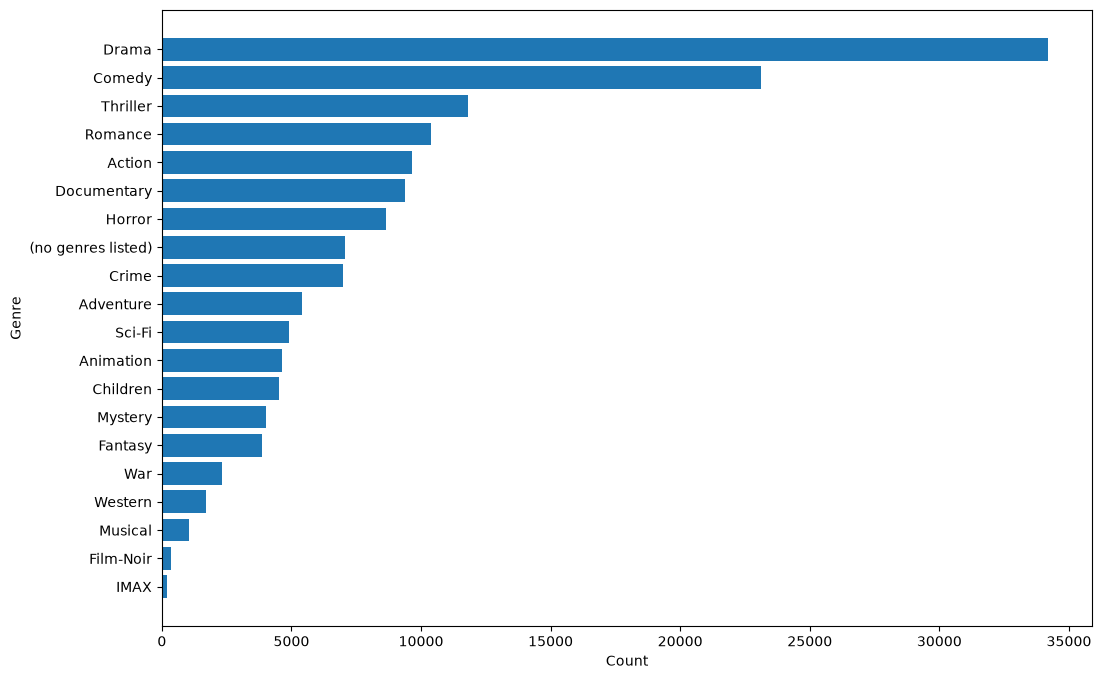

In [74]:
from collections import Counter 

genre_counts = Counter(genre_list)

genre_list_ = list(genre_counts.keys())
genre_list_.sort(key = lambda genre: genre_counts[genre], reverse=False)

genre_count_ = list(genre_counts.values())
genre_count_.sort(reverse=False)

plt.figure(figsize=(12,8))
plt.barh( genre_list_, genre_count_)
plt.xlabel("Count")
plt.ylabel("Genre")

plt.savefig("images/genre_distribution.svg")
plt.show()